# CDA《商业数据分析》第2章图表复现

本 Notebook 直接读取“第2章 数据分析方法”中的 Excel 文件，复现以下图表：

1. 波士顿矩阵
2. RFM 用户分类与帕累托图
3. 用户忠诚度分层
4. 同期群留存热力图
5. 销售漏斗图
6. 相关分析散点图
7. 趋势、对比、分布、构成、关系分析图
8. 桑基图

> 运行方式：在 Jupyter 中从上到下执行即可。代码不使用 `__file__`，因此可在 Notebook 环境直接运行。

> GitHub 版本使用仓库内 `data/` 目录，不依赖本机绝对路径。

In [1]:
# 如果缺少依赖，取消下一行注释后运行一次：
# %pip install pandas numpy matplotlib seaborn openpyxl plotly

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.ticker as mtick
import seaborn as sns
import plotly.graph_objects as go
from openpyxl import load_workbook
from IPython.display import display

warnings.filterwarnings("ignore", category=UserWarning)

# 教材第2章路径；如果你移动了文件夹，只需修改这一行。
PROJECT_DIR = Path.cwd()
BASE_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = Path.cwd() / "chapter2_chart_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not BASE_DIR.exists():
    raise FileNotFoundError(f"未找到教材文件夹：{BASE_DIR}")

# 中文字体自动选择。
available_fonts = {font.name for font in fm.fontManager.ttflist}
for candidate in ["Microsoft YaHei", "SimHei", "Noto Sans CJK SC", "Arial Unicode MS"]:
    if candidate in available_fonts:
        plt.rcParams["font.sans-serif"] = [candidate]
        break
plt.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", font=plt.rcParams["font.sans-serif"][0])

COLORS = ["#2F5597", "#5B9BD5", "#70AD47", "#FFC000", "#ED7D31", "#A5A5A5", "#4472C4", "#264478"]

def find_book(filename):
    # 在第2章目录中递归查找工作簿，避免手写很长的中文子目录。
    hits = list(BASE_DIR.rglob(filename))
    if not hits:
        raise FileNotFoundError(f"未找到：{filename}")
    return hits[0]

def cached_range(filename, sheet_name, cell_range):
    # 读取 Excel 中保存的公式结果，适合复现参考答案的随机示例数据。
    wb = load_workbook(find_book(filename), data_only=True, read_only=True)
    ws = wb[sheet_name]
    values = [[cell.value for cell in row] for row in ws[cell_range]]
    wb.close()
    return pd.DataFrame(values)

def save_show(fig, filename, tight=True):
    if tight:
        fig.tight_layout()
    fig.savefig(OUTPUT_DIR / filename, dpi=180, bbox_inches="tight", facecolor="white")
    plt.show()

print("教材路径：", BASE_DIR)
print("图片输出：", OUTPUT_DIR)

教材路径： C:\Users\sangchenge\Documents\Codex\2026-10-21\w\outputs\cda-chapter2-data-visualization\data
图片输出： C:\Users\sangchenge\Documents\Codex\2026-10-21\w\outputs\cda-chapter2-data-visualization\chapter2_chart_outputs


## 1. 波士顿矩阵

以8月销售额占比为横轴，7月到8月的销售增长率为纵轴。竖直分割线为各品牌平均市场占有率，水平分割线为整体市场环比增长率。

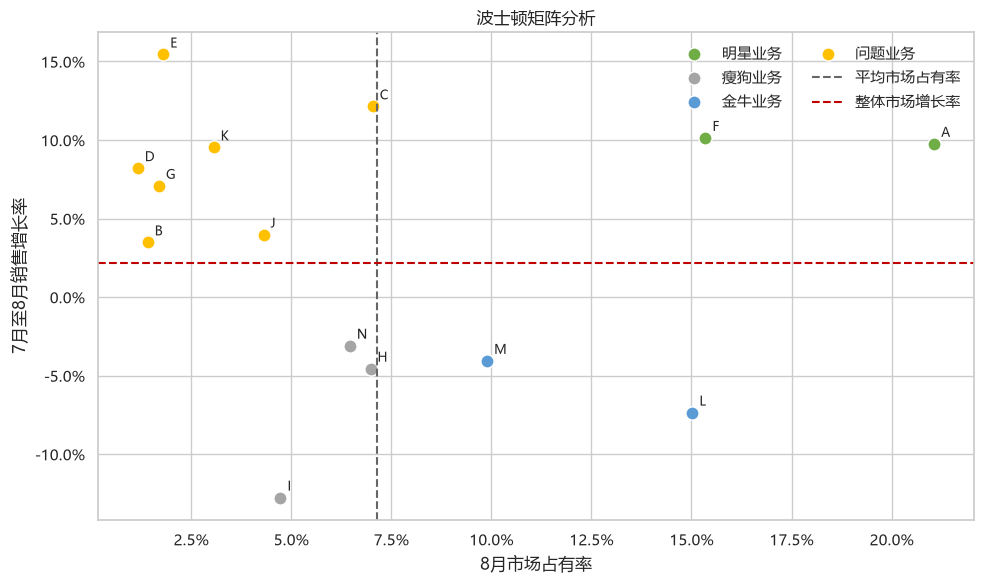

月份,7月销售额,8月销售额,市场占有率,销售增长率,象限
品牌,,,,,
A,55867.3,61321.1,0.2106,0.0976,明星业务
B,3979.8,4118.4,0.0141,0.0348,问题业务
C,18273.5,20492.3,0.0704,0.1214,问题业务
D,3138.7,3396.4,0.0117,0.0821,问题业务
E,4545.8,5247.9,0.0180,0.1545,问题业务
F,40574.8,44687.3,0.1535,0.1014,明星业务
G,4614.2,4941.0,0.0170,0.0708,问题业务
H,21295.0,20325.0,0.0698,-0.0456,瘦狗业务
I,15792.0,13776.0,0.0473,-0.1277,瘦狗业务


In [2]:
boston_path = find_book("1-1波士顿矩阵.xlsx")
sales = pd.read_excel(boston_path, sheet_name="销售表", usecols="A:F")
sales["销售日期"] = pd.to_datetime(sales["销售日期"])
sales["订单金额"] = pd.to_numeric(sales["单价"], errors="coerce") * pd.to_numeric(sales["销量"], errors="coerce")
sales["月份"] = sales["销售日期"].dt.month

boston = sales.pivot_table(index="品牌", columns="月份", values="订单金额", aggfunc="sum", fill_value=0)
boston = boston.rename(columns={7: "7月销售额", 8: "8月销售额"})
boston["市场占有率"] = boston["8月销售额"] / boston["8月销售额"].sum()
boston["销售增长率"] = boston["8月销售额"].div(boston["7月销售额"]).sub(1)

share_cut = boston["市场占有率"].mean()
growth_cut = boston["8月销售额"].sum() / boston["7月销售额"].sum() - 1

def quadrant(row):
    if row["市场占有率"] >= share_cut and row["销售增长率"] >= growth_cut:
        return "明星业务"
    if row["市场占有率"] >= share_cut:
        return "金牛业务"
    if row["销售增长率"] >= growth_cut:
        return "问题业务"
    return "瘦狗业务"

boston["象限"] = boston.apply(quadrant, axis=1)
palette = {"明星业务": "#70AD47", "金牛业务": "#5B9BD5", "问题业务": "#FFC000", "瘦狗业务": "#A5A5A5"}

fig, ax = plt.subplots(figsize=(10, 6))
for group, part in boston.groupby("象限"):
    ax.scatter(part["市场占有率"], part["销售增长率"], s=90, color=palette[group], label=group, edgecolor="white")
for brand, row in boston.iterrows():
    ax.annotate(str(brand), (row["市场占有率"], row["销售增长率"]), xytext=(5, 5), textcoords="offset points", fontsize=9)
ax.axvline(share_cut, color="#666666", linestyle="--", label="平均市场占有率")
ax.axhline(growth_cut, color="#C00000", linestyle="--", label="整体市场增长率")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set(title="波士顿矩阵分析", xlabel="8月市场占有率", ylabel="7月至8月销售增长率")
ax.legend(ncol=2, frameon=False)
save_show(fig, "01_波士顿矩阵.png")
display(boston.round(4))

## 2. RFM 模型与帕累托图

R 表示距分析时点的最近消费间隔，F 表示去重后的消费频次，M 表示消费金额。依据教材的高/低规则将用户分为 8 类，再观察各类用户的消费贡献及累计占比。

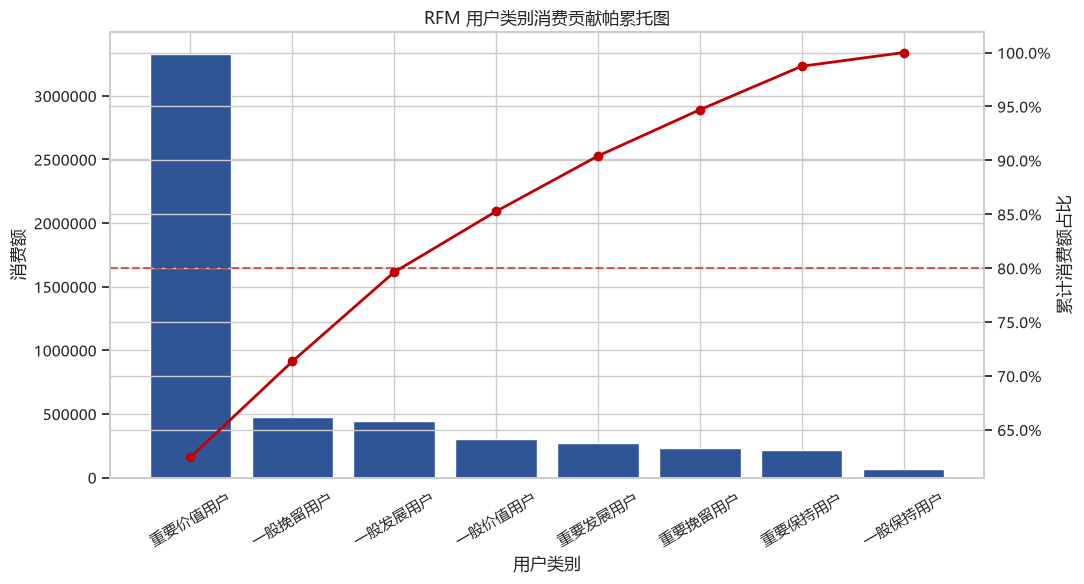

,用户数,消费额,累计消费额占比
用户类别,,,
重要价值用户,1324,3332337.04,0.624
一般挽留用户,2560,474480.41,0.713
一般发展用户,2026,442203.79,0.796
一般价值用户,658,300764.97,0.853
重要发展用户,180,274398.75,0.904
重要挽留用户,148,228826.03,0.947
重要保持用户,126,215488.51,0.987
一般保持用户,156,67686.60,1.000


In [3]:
rfm_path = find_book("1-2RFM模型.xlsx")
tx = pd.read_excel(rfm_path, sheet_name="原始数据", usecols="A:H")
tx["销售日期"] = pd.to_datetime(tx["销售日期"])
tx["销售金额"] = pd.to_numeric(tx["销售金额"], errors="coerce").fillna(0)
analysis_date = pd.Timestamp("2019-08-03")

rfm = tx.groupby("用户编号").agg(
    最近一次消费日期=("销售日期", "max"),
    F=("流水号", "nunique"),
    M=("销售金额", "sum")
)
rfm["R"] = (analysis_date - rfm["最近一次消费日期"]).dt.days
r_cut, f_cut, m_cut = rfm["R"].mean(), rfm["F"].mean(), rfm["M"].mean()
rfm["R程度"] = np.where(rfm["R"] < r_cut, "高", "低")
rfm["F程度"] = np.where(rfm["F"] > f_cut, "高", "低")
rfm["M程度"] = np.where(rfm["M"] > m_cut, "高", "低")

segment_map = {
    "高高高": "重要价值用户", "高低高": "重要发展用户", "低高高": "重要保持用户", "低低高": "重要挽留用户",
    "高高低": "一般价值用户", "高低低": "一般发展用户", "低高低": "一般保持用户", "低低低": "一般挽留用户"
}
rfm["用户类别"] = (rfm["R程度"] + rfm["F程度"] + rfm["M程度"]).map(segment_map)
segment = rfm.groupby("用户类别").agg(用户数=("M", "size"), 消费额=("M", "sum")).sort_values("消费额", ascending=False)
segment["累计消费额占比"] = segment["消费额"].cumsum() / segment["消费额"].sum()

fig, ax1 = plt.subplots(figsize=(11, 6))
bars = ax1.bar(segment.index, segment["消费额"], color=COLORS[0])
ax1.set_ylabel("消费额")
ax1.set_xlabel("用户类别")
ax1.tick_params(axis="x", rotation=30)
ax1.ticklabel_format(style="plain", axis="y")
ax2 = ax1.twinx()
ax2.plot(segment.index, segment["累计消费额占比"], color="#C00000", marker="o", linewidth=2)
ax2.axhline(0.8, color="#C00000", linestyle="--", alpha=.6)
ax2.set_ylabel("累计消费额占比")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax1.set_title("RFM 用户类别消费贡献帕累托图")
save_show(fig, "02_RFM帕累托图.png")
display(segment.round(3))

## 3. 用户忠诚度模型

先排除教材定义的“潜在用户”和“易流失用户”，然后对剩余用户的消费频次 F 和消费金额 M 使用 25% / 75% 分位数评分。总分用于区分忠诚、进阶、普通和低价值用户。

C:\Users\SANGCH~1\AppData\Local\Temp\ipykernel_23348\1143103839.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=loyalty.index, y=loyalty["用户数"], ax=axes[0], palette=COLORS[:4])
C:\Users\SANGCH~1\AppData\Local\Temp\ipykernel_23348\1143103839.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=loyalty.index, y=loyalty["消费额"], ax=axes[1], palette=COLORS[:4])


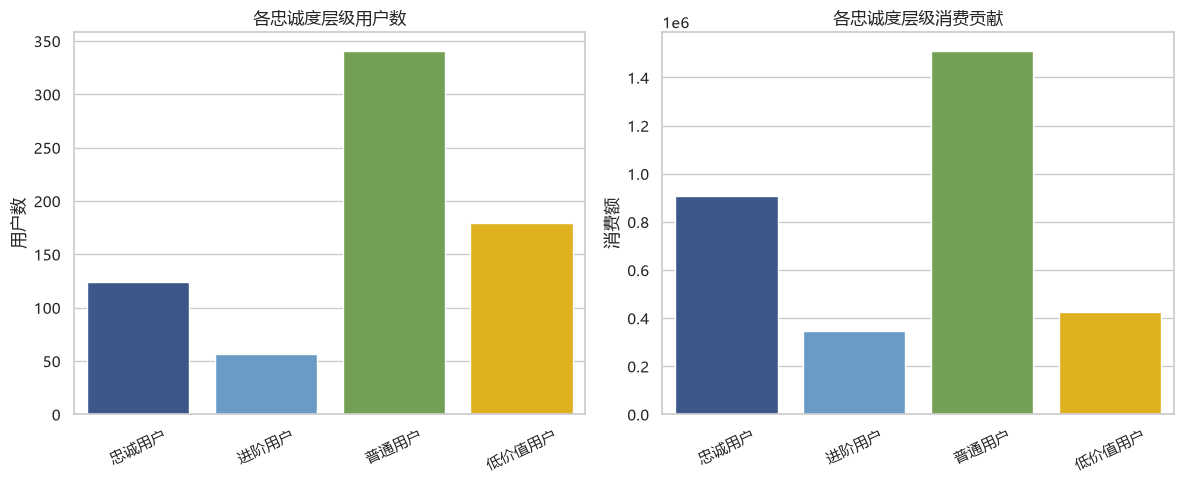

排除潜在用户 10 人，易流失用户 279 人；参与评分 701 人。


,用户数,消费额
用户类别,,
忠诚用户,124,908228
进阶用户,57,346785
普通用户,341,1512078
低价值用户,179,426440


In [4]:
loyalty_path = find_book("1-3用户忠诚度模型.xlsx")
flow = pd.read_excel(loyalty_path, sheet_name="销售流水表", usecols="A:E")
flow["消费日期"] = pd.to_datetime(flow["消费日期"])
flow["消费金额"] = pd.to_numeric(flow["消费金额"], errors="coerce").fillna(0)
analysis_date = pd.Timestamp("2021-01-01")
cutoff = analysis_date - pd.Timedelta(weeks=13)

order_period = flow.assign(是否最近13周内消费=np.where(flow["消费日期"] > cutoff, "是", "否"))
counts = order_period.pivot_table(index="会员编号", columns="是否最近13周内消费", values="订单编号", aggfunc=pd.Series.nunique, fill_value=0)
for col in ["是", "否"]:
    if col not in counts:
        counts[col] = 0
potential = counts[(counts["否"] == 0) & (counts["是"] == 1)].index
churn = counts[counts["是"] == 0].index
excluded = set(potential) | set(churn)

active = flow[~flow["会员编号"].isin(excluded)].groupby("会员编号").agg(
    消费次数=("订单编号", "nunique"), 消费额=("消费金额", "sum")
)
f_q1, f_q3 = active["消费次数"].quantile([.25, .75])
m_q1, m_q3 = active["消费额"].quantile([.25, .75])

def score(series, q1, q3):
    return np.select([series < q1, series > q3], [1, 3], default=2)

active["F评分"] = score(active["消费次数"], f_q1, f_q3)
active["M评分"] = score(active["消费额"], m_q1, m_q3)
active["总分"] = active["F评分"] + active["M评分"]
active["用户类别"] = active["总分"].map({6: "忠诚用户", 5: "进阶用户", 4: "普通用户", 3: "低价值用户", 2: "低价值用户"})
loyalty = active.groupby("用户类别").agg(用户数=("总分", "size"), 消费额=("消费额", "sum")).reindex(["忠诚用户", "进阶用户", "普通用户", "低价值用户"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.barplot(x=loyalty.index, y=loyalty["用户数"], ax=axes[0], palette=COLORS[:4])
axes[0].set(title="各忠诚度层级用户数", xlabel="", ylabel="用户数")
sns.barplot(x=loyalty.index, y=loyalty["消费额"], ax=axes[1], palette=COLORS[:4])
axes[1].set(title="各忠诚度层级消费贡献", xlabel="", ylabel="消费额")
for ax in axes:
    ax.tick_params(axis="x", rotation=25)
save_show(fig, "03_用户忠诚度分层.png")
print(f"排除潜在用户 {len(potential)} 人，易流失用户 {len(churn)} 人；参与评分 {len(active)} 人。")
display(loyalty)

## 4. 同期群留存热力图

每一行是同一注册日期的用户群，每一列是注册后第 0–15 日。留存率为该日仍登录的去重用户数除以当日新增用户数。

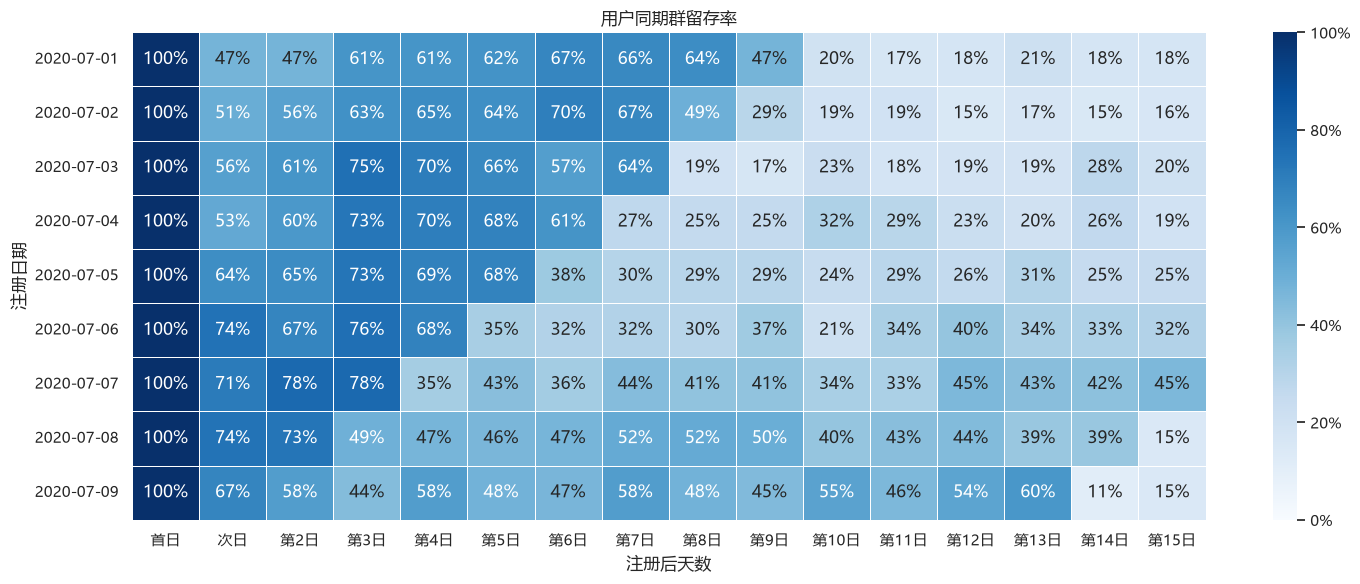

In [5]:
cohort_path = find_book("1-4同期群分析.xlsx")
login = pd.read_excel(cohort_path, sheet_name="用户登录明细", usecols="A:C")
login["注册日期"] = pd.to_datetime(login["注册日期"]).dt.normalize()
login["登录日期"] = pd.to_datetime(login["登录时点"]).dt.normalize()
login["第几日"] = (login["登录日期"] - login["注册日期"]).dt.days
login = login[login["第几日"].between(0, 15)]
cohort_size = login.groupby("注册日期")["用户编号"].nunique()
retained = login.pivot_table(index="注册日期", columns="第几日", values="用户编号", aggfunc="nunique", fill_value=0)
retention = retained.div(cohort_size, axis=0).reindex(columns=range(16), fill_value=0)
retention.index = retention.index.strftime("%Y-%m-%d")
retention.columns = ["首日", "次日"] + [f"第{i}日" for i in range(2, 16)]

fig, ax = plt.subplots(figsize=(15, 6))
sns.heatmap(retention, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, linewidths=.4, cbar_kws={"format": mtick.PercentFormatter(1)}, ax=ax)
ax.set(title="用户同期群留存率", xlabel="注册后天数", ylabel="注册日期")
save_show(fig, "04_同期群留存热力图.png")

## 5. 销售漏斗图

各阶段用户数逐级减少。条形居中对齐，并同时标注上一阶段转化率和总体转化率。

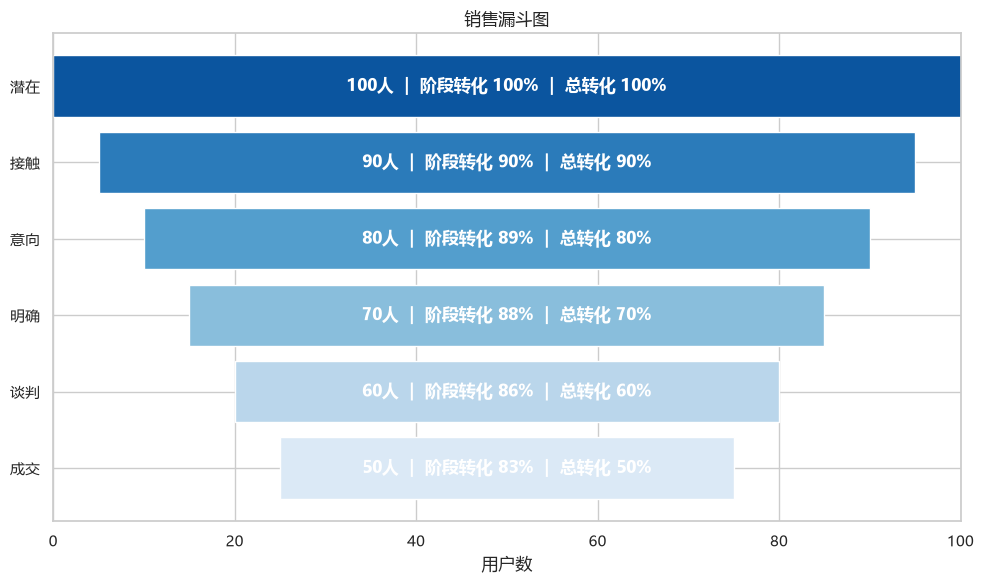

In [6]:
funnel_raw = cached_range("2-1漏斗图-参考.xlsx", "Sheet1", "A3:E9")
funnel_raw.columns = funnel_raw.iloc[0]
funnel = funnel_raw.iloc[1:].reset_index(drop=True)
for col in ["用户数", "转化率", "总体转化率"]:
    funnel[col] = pd.to_numeric(funnel[col], errors="coerce")

max_value = funnel["用户数"].max()
left = (max_value - funnel["用户数"]) / 2
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(funnel["阶段"], funnel["用户数"], left=left, color=sns.color_palette("Blues_r", len(funnel)))
ax.invert_yaxis()
for bar, (_, row) in zip(bars, funnel.iterrows()):
    ax.text(max_value / 2, bar.get_y() + bar.get_height()/2, f"{int(row['用户数'])}人  |  阶段转化 {row['转化率']:.0%}  |  总转化 {row['总体转化率']:.0%}", ha="center", va="center", color="white", fontweight="bold")
ax.set(title="销售漏斗图", xlabel="用户数", ylabel="")
ax.set_xlim(0, max_value)
save_show(fig, "05_销售漏斗图.png")

## 6. 相关分析

散点图展示 x 与 y 的关系，图中增加一元线性回归线，并标注 Pearson 相关系数。

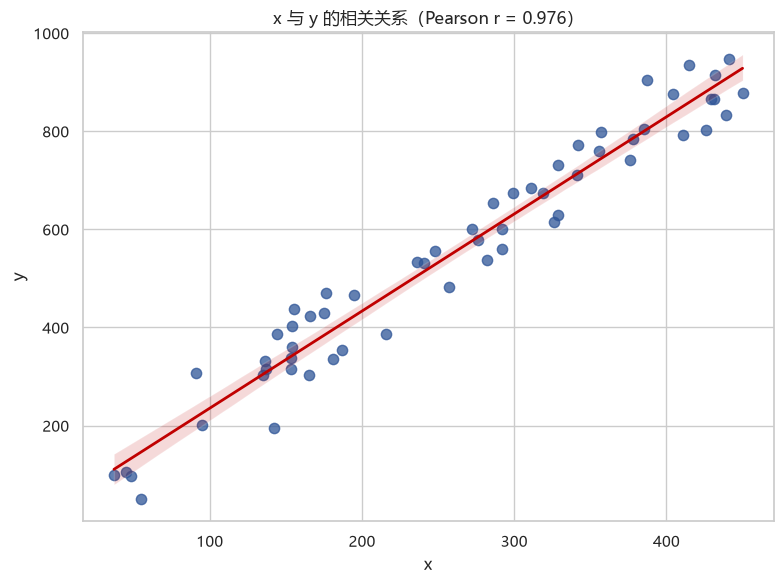

In [7]:
corr_path = find_book("3-1相关分析.xlsx")
corr_data = pd.read_excel(corr_path, sheet_name="原始数据", usecols="A:B").dropna()
corr_data = corr_data.apply(pd.to_numeric, errors="coerce").dropna()
r = corr_data["x"].corr(corr_data["y"])

fig, ax = plt.subplots(figsize=(8, 6))
sns.regplot(data=corr_data, x="x", y="y", scatter_kws={"s": 55, "alpha": .75, "color": COLORS[0]}, line_kws={"color": "#C00000", "linewidth": 2}, ax=ax)
ax.set_title(f"x 与 y 的相关关系（Pearson r = {r:.3f}）")
save_show(fig, "06_相关分析散点图.png")

## 7. 趋势分析

分别复现长期年度趋势、周度波动及预警线、月度订单量与环比增幅。

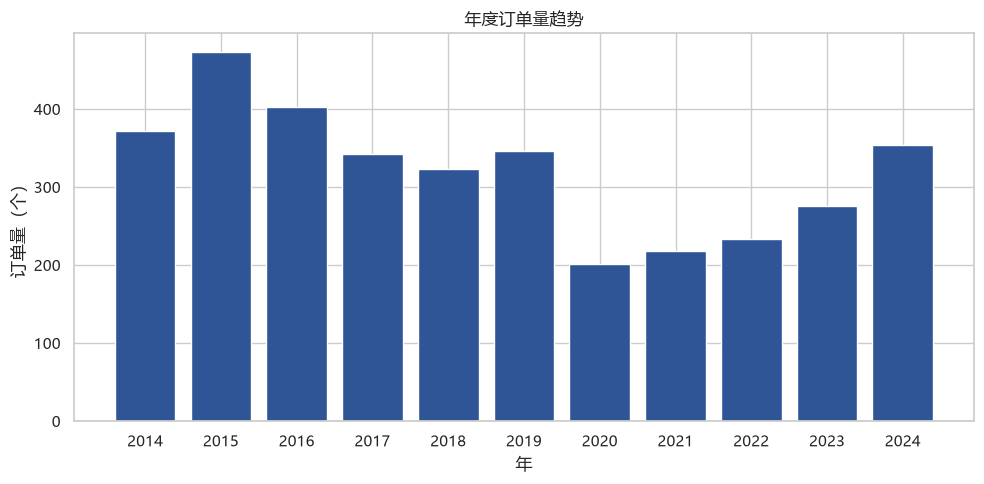

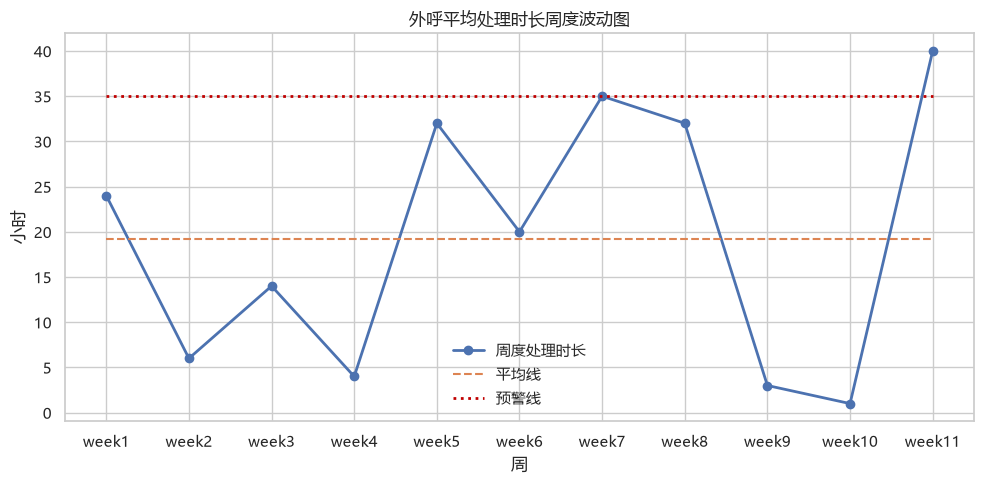

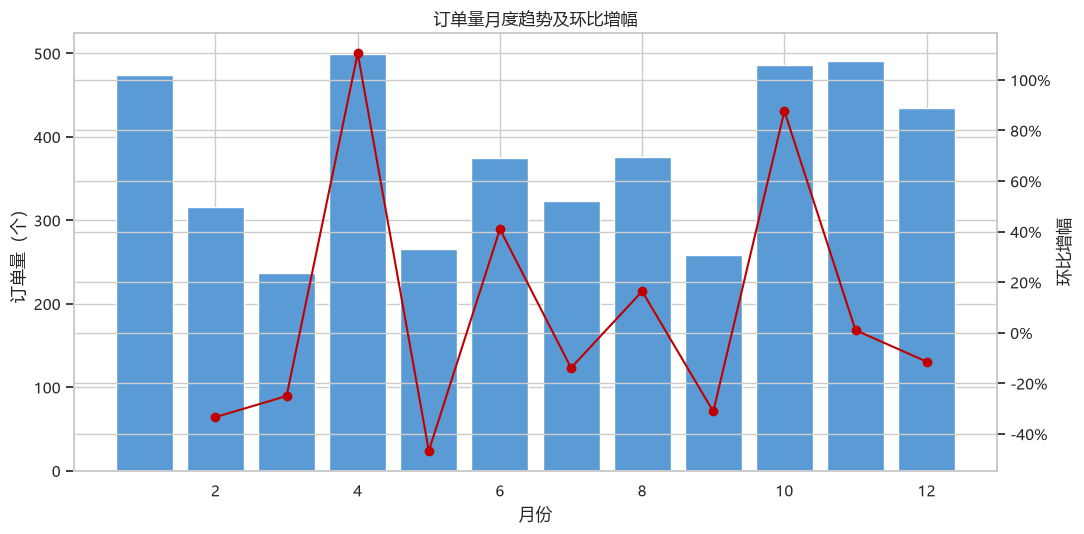

In [8]:
yearly = cached_range("1趋势分析-参考.xlsx", "趋势图", "B2:C13")
yearly.columns = yearly.iloc[0]
yearly = yearly.iloc[1:].apply(pd.to_numeric, errors="coerce")

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(yearly["year"].astype(int).astype(str), yearly["订单量（单位：个）"], color=COLORS[0])
ax.set(title="年度订单量趋势", xlabel="年", ylabel="订单量（个）")
save_show(fig, "07a_年度订单趋势.png")

weekly = cached_range("1趋势分析-参考.xlsx", "趋势图", "B18:E29")
weekly.columns = weekly.iloc[0]
weekly = weekly.iloc[1:].reset_index(drop=True)
for col in weekly.columns[1:]:
    weekly[col] = pd.to_numeric(weekly[col], errors="coerce")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(weekly["周"], weekly["平均处理时长（单位：小时）"], marker="o", linewidth=2, label="周度处理时长")
ax.plot(weekly["周"], weekly["平均时长（单位：小时）"], linestyle="--", label="平均线")
ax.plot(weekly["周"], weekly["预警值"], color="#C00000", linestyle=":", linewidth=2, label="预警线")
ax.set(title="外呼平均处理时长周度波动图", xlabel="周", ylabel="小时")
ax.legend(frameon=False)
save_show(fig, "07b_周度波动与预警线.png")

monthly = cached_range("1趋势分析-参考.xlsx", "趋势图", "B35:D47")
monthly.columns = monthly.iloc[0]
monthly = monthly.iloc[1:].reset_index(drop=True)
for col in monthly.columns:
    monthly[col] = pd.to_numeric(monthly[col], errors="coerce")

fig, ax1 = plt.subplots(figsize=(11, 5.5))
ax1.bar(monthly["月"].astype(int), monthly["订单量（单位：个）"], color=COLORS[1], label="订单量")
ax1.set(xlabel="月份", ylabel="订单量（个）")
ax2 = ax1.twinx()
ax2.plot(monthly["月"], monthly["环比增幅"], color="#C00000", marker="o", label="环比增幅")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax2.set_ylabel("环比增幅")
ax1.set_title("订单量月度趋势及环比增幅")
save_show(fig, "07c_月度趋势及环比.png")

## 8. 对比分析

竖向柱形图适合类别较少且标签较短的场景；水平条形图更适合较长的类别名称；雷达图用于展示多维画像。

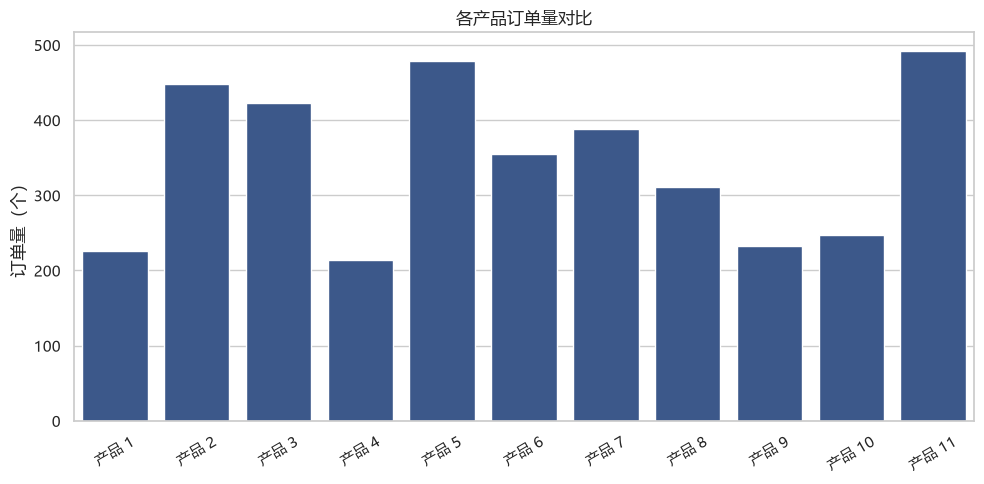

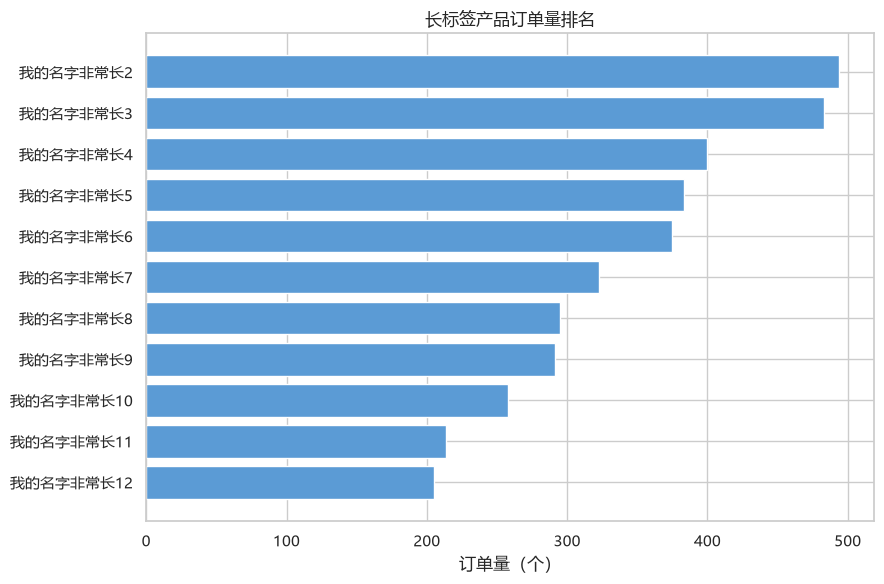

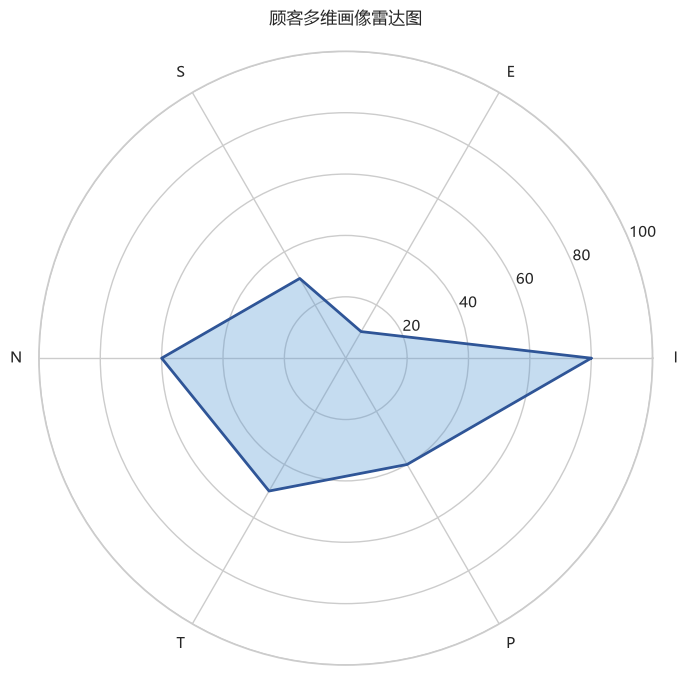

In [9]:
compare1 = cached_range("2对比分析-参考.xlsx", "对比分析", "B2:C13")
compare1.columns = compare1.iloc[0]
compare1 = compare1.iloc[1:]
compare1.iloc[:, 1] = pd.to_numeric(compare1.iloc[:, 1])

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=compare1, x="产品类型", y="订单量（单位：个）", color=COLORS[0], ax=ax)
ax.set(title="各产品订单量对比", xlabel="", ylabel="订单量（个）")
ax.tick_params(axis="x", rotation=30)
save_show(fig, "08a_产品订单量对比.png")

compare2 = cached_range("2对比分析-参考.xlsx", "对比分析", "B18:C29")
compare2.columns = compare2.iloc[0]
compare2 = compare2.iloc[1:]
compare2.iloc[:, 1] = pd.to_numeric(compare2.iloc[:, 1])
compare2 = compare2.sort_values(compare2.columns[1])

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(compare2.iloc[:, 0], compare2.iloc[:, 1], color=COLORS[1])
ax.set(title="长标签产品订单量排名", xlabel="订单量（个）", ylabel="")
save_show(fig, "08b_水平条形对比.png")

profile = cached_range("2对比分析-参考.xlsx", "对比分析", "B38:C44")
profile.columns = profile.iloc[0]
profile = profile.iloc[1:]
labels = profile.iloc[:, 0].astype(str).tolist()
values = pd.to_numeric(profile.iloc[:, 1]).tolist()
angles = np.linspace(0, 2*np.pi, len(labels), endpoint=False).tolist()
values_closed, angles_closed = values + values[:1], angles + angles[:1]
fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={"polar": True})
ax.plot(angles_closed, values_closed, color=COLORS[0], linewidth=2)
ax.fill(angles_closed, values_closed, color=COLORS[1], alpha=.35)
ax.set_xticks(angles, labels)
ax.set_ylim(0, 100)
ax.set_title("顾客多维画像雷达图", pad=20)
save_show(fig, "08c_顾客画像雷达图.png")

## 9. 分布分析

时序线图展示客流量随时间的波动，直方图与核密密度曲线展示年龄分布，箱线图用于识别客单价的中心、离散程度和异常值。

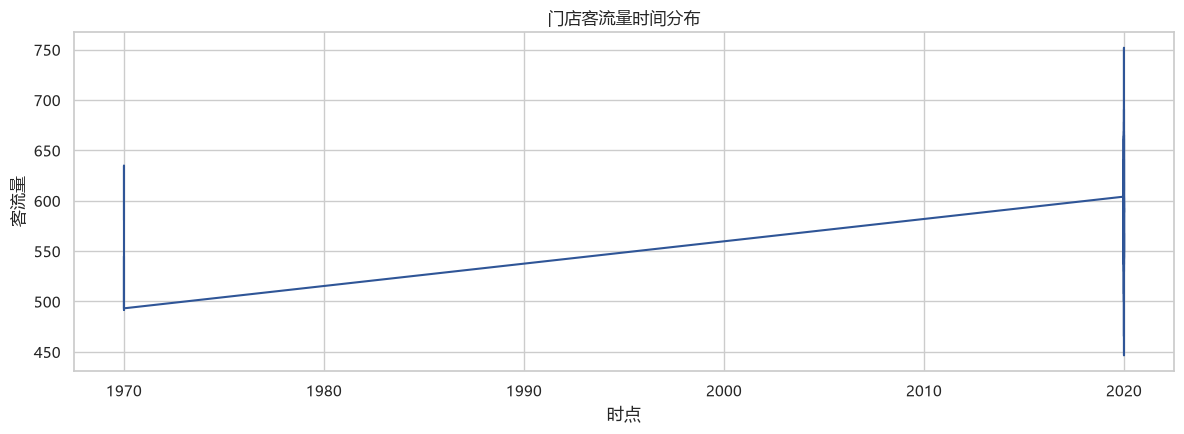

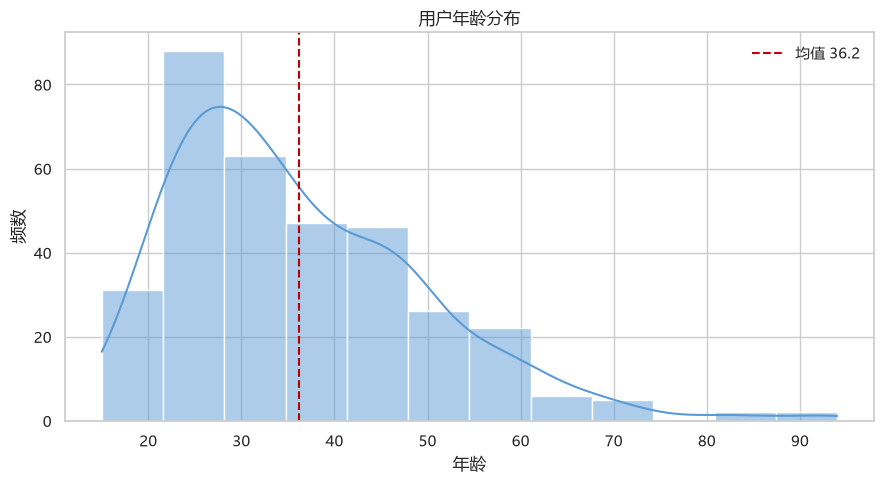

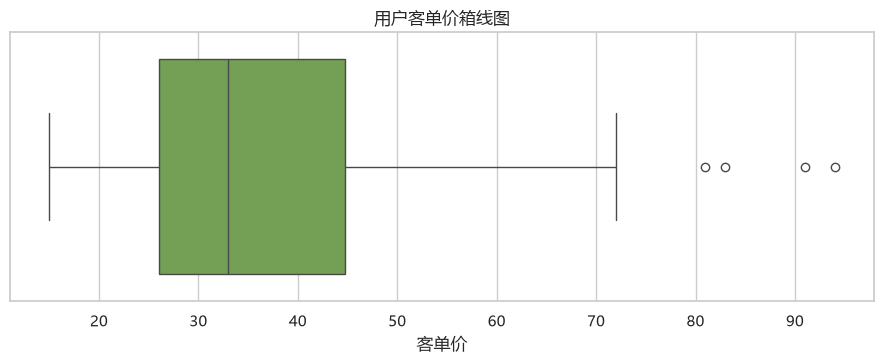

In [10]:
dist_path = find_book("3分布分析-参考.xlsx")
traffic = pd.read_excel(dist_path, sheet_name="分布分析", usecols="B:C", header=1, nrows=337).dropna()
traffic["时点"] = pd.to_datetime(traffic["时点"], errors="coerce")
traffic["门店客流量"] = pd.to_numeric(traffic["门店客流量"], errors="coerce")
traffic = traffic.dropna(subset=["时点", "门店客流量"])

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(traffic["时点"], traffic["门店客流量"], color=COLORS[0], linewidth=1.5)
ax.set(title="门店客流量时间分布", xlabel="时点", ylabel="客流量")
save_show(fig, "09a_客流量时间分布.png")

age = pd.read_excel(dist_path, sheet_name="分布分析", usecols="K:L", header=1).iloc[:, 1]
age = pd.to_numeric(age, errors="coerce").dropna()
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(age, bins=12, kde=True, color=COLORS[1], ax=ax)
ax.axvline(age.mean(), color="#C00000", linestyle="--", label=f"均值 {age.mean():.1f}")
ax.set(title="用户年龄分布", xlabel="年龄", ylabel="频数")
ax.legend(frameon=False)
save_show(fig, "09b_用户年龄分布.png")

unit_price = pd.read_excel(dist_path, sheet_name="分布分析", usecols="T:U", header=0).iloc[:, 1]
unit_price = pd.to_numeric(unit_price, errors="coerce").dropna()
fig, ax = plt.subplots(figsize=(9, 3.8))
sns.boxplot(x=unit_price, color=COLORS[2], ax=ax)
ax.set(title="用户客单价箱线图", xlabel="客单价")
save_show(fig, "09c_客单价箱线图.png")

## 10. 构成分析

饼图/环形图展示单个时点的产品构成，分组柱形图展示多年各产品的绝对量对比，堆积面积图展示总量及内部构成的同步变化。

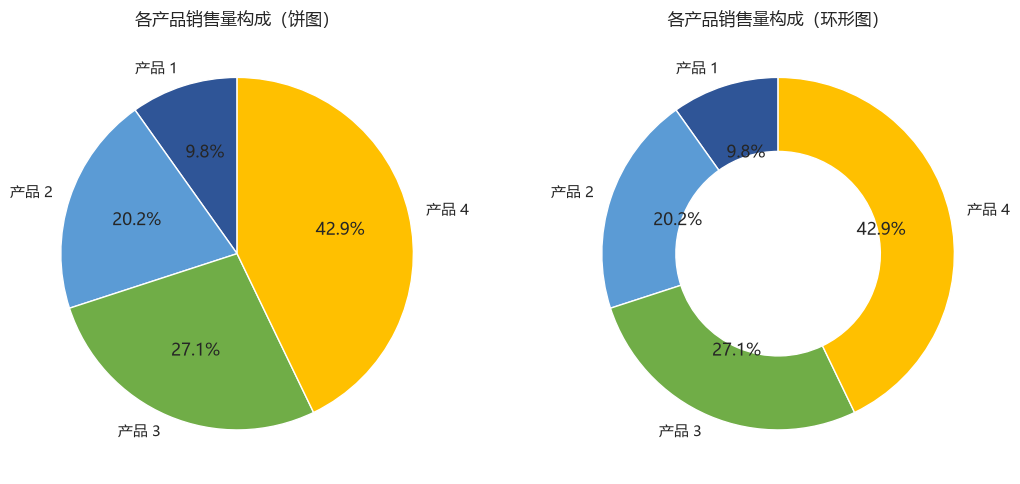

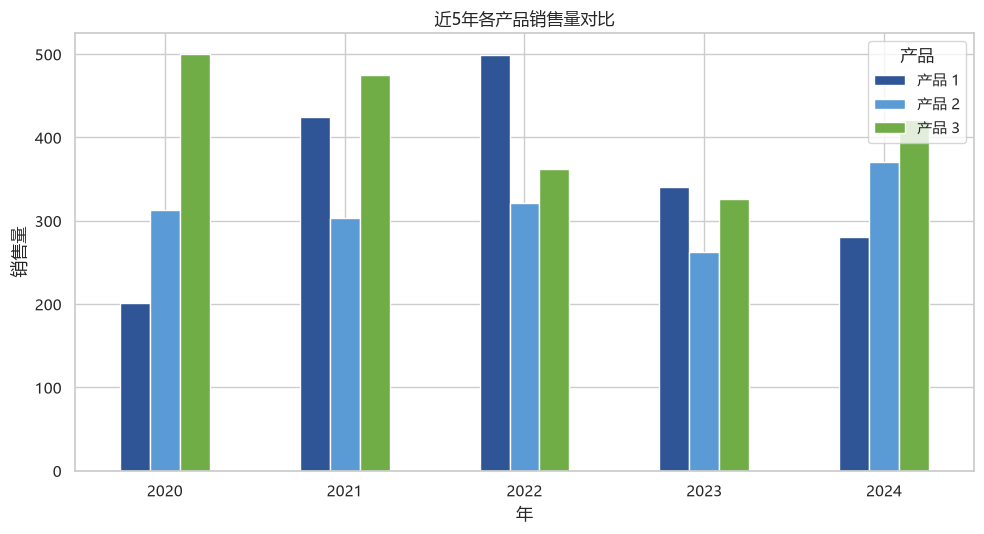

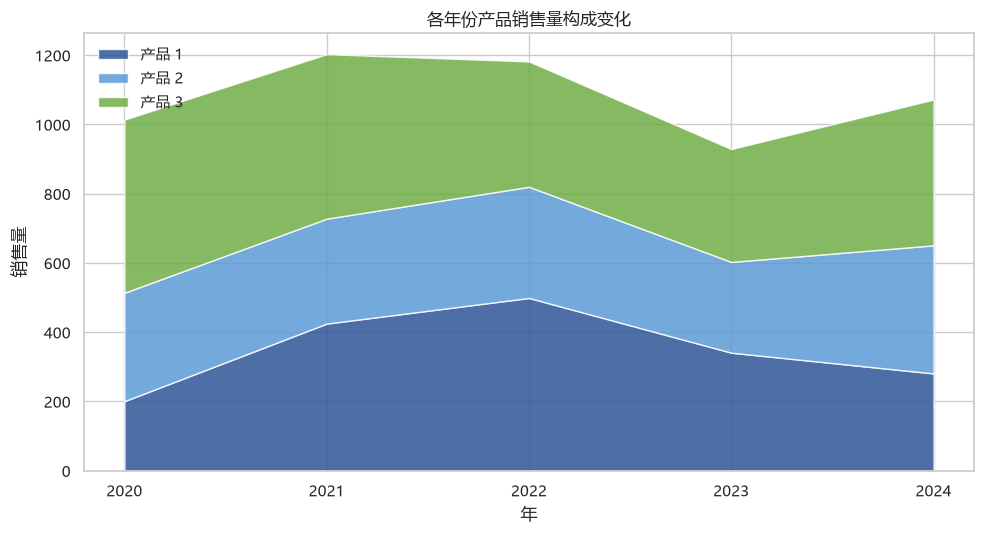

In [11]:
composition = cached_range("4构成分析-参考.xlsx", "构成分析", "B4:C8")
composition.columns = composition.iloc[0]
composition = composition.iloc[1:]
composition_labels = composition.iloc[:, 0].astype(str).to_numpy()
composition_values = pd.to_numeric(composition.iloc[:, 1], errors="coerce").to_numpy(dtype=float)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].pie(composition_values, labels=composition_labels, autopct="%1.1f%%", colors=COLORS[:4], startangle=90)
axes[0].set_title("各产品销售量构成（饼图）")
axes[1].pie(composition_values, labels=composition_labels, autopct="%1.1f%%", colors=COLORS[:4], startangle=90, wedgeprops={"width": .42, "edgecolor": "white"})
axes[1].set_title("各产品销售量构成（环形图）")
save_show(fig, "10a_饼图与环形图.png")

multi = cached_range("4构成分析-参考.xlsx", "构成分析", "B17:E22")
multi.columns = multi.iloc[0]
multi = multi.iloc[1:].set_index("年/产品类型").apply(pd.to_numeric, errors="coerce")

fig, ax = plt.subplots(figsize=(10, 5.5))
multi.plot(kind="bar", color=COLORS[:3], ax=ax)
ax.set(title="近5年各产品销售量对比", xlabel="年", ylabel="销售量")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="产品")
save_show(fig, "10b_多年产品销售对比.png")

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.stackplot(multi.index.astype(str), *[multi[c] for c in multi.columns], labels=multi.columns, colors=COLORS[:3], alpha=.85)
ax.set(title="各年份产品销售量构成变化", xlabel="年", ylabel="销售量")
ax.legend(loc="upper left", frameon=False)
save_show(fig, "10c_堆积面积图.png")

## 11. 关系分析

分组柱形图比较各营销活动的下单/未下单用户；百分比堆积图比较不同忠诚度下的满意度构成；散点图及回归线用于分析投入与产出的关系。

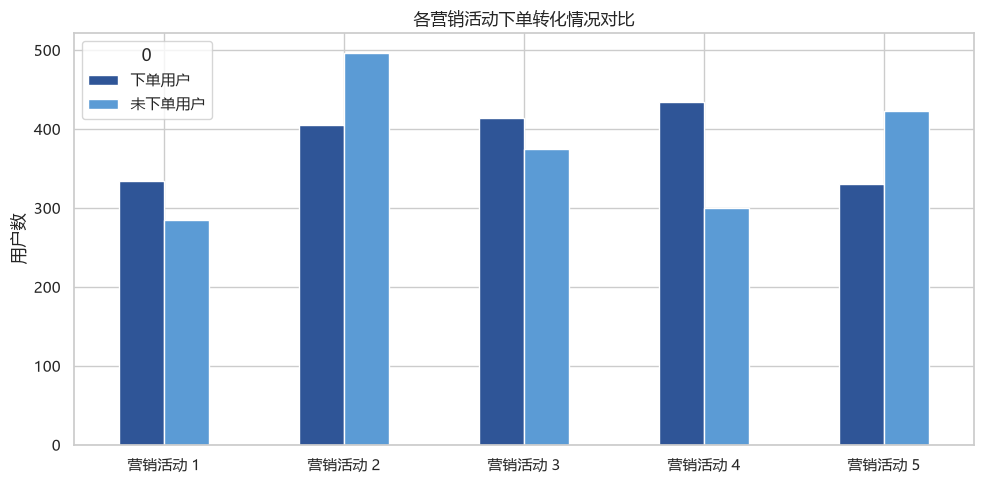

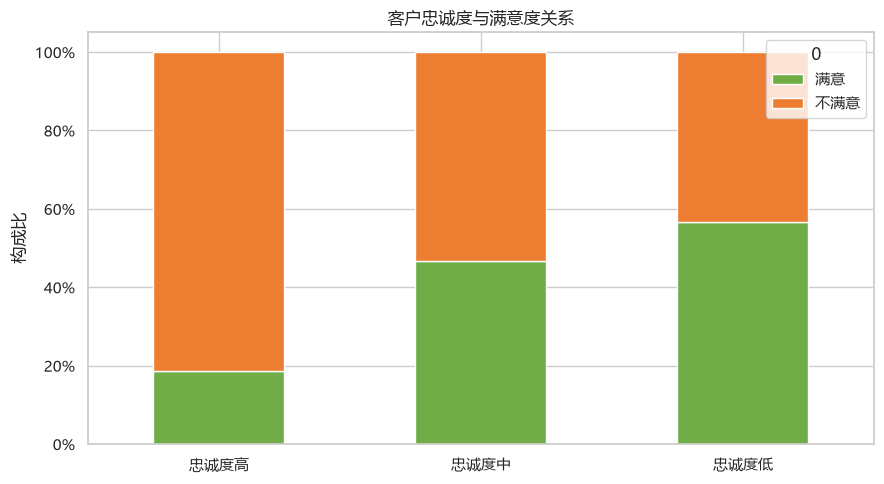

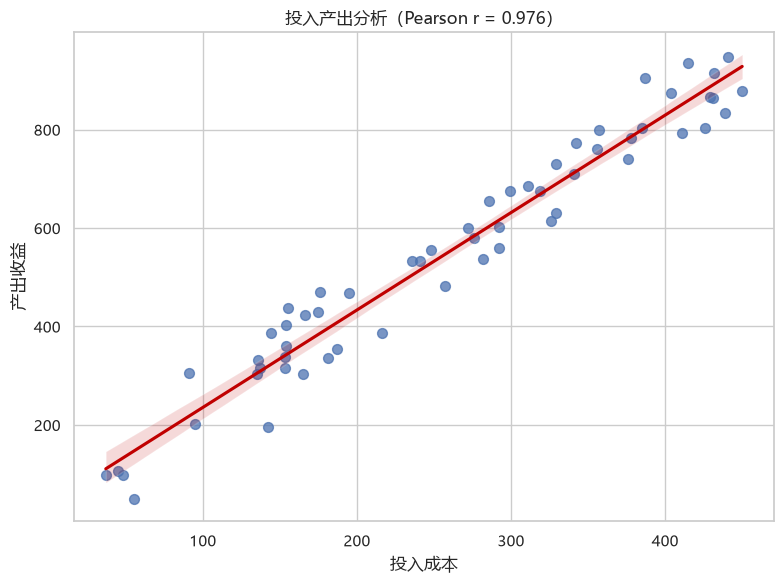

In [12]:
campaign = cached_range("5关系分析-参考.xlsx", "关系图", "B3:D8")
campaign.columns = campaign.iloc[0]
campaign = campaign.iloc[1:].set_index("地区/人数").apply(pd.to_numeric, errors="coerce")

fig, ax = plt.subplots(figsize=(10, 5))
campaign.plot(kind="bar", color=COLORS[:2], ax=ax)
ax.set(title="各营销活动下单转化情况对比", xlabel="", ylabel="用户数")
ax.tick_params(axis="x", rotation=0)
save_show(fig, "11a_营销活动转化对比.png")

satisfaction = cached_range("5关系分析-参考.xlsx", "关系图", "B15:D18")
satisfaction.columns = satisfaction.iloc[0]
satisfaction = satisfaction.iloc[1:].set_index("忠诚度").apply(pd.to_numeric, errors="coerce")
satisfaction_pct = satisfaction.div(satisfaction.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(9, 5))
satisfaction_pct.plot(kind="bar", stacked=True, color=[COLORS[2], "#ED7D31"], ax=ax)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set(title="客户忠诚度与满意度关系", xlabel="", ylabel="构成比")
ax.tick_params(axis="x", rotation=0)
save_show(fig, "11b_忠诚度与满意度.png")

relation_path = find_book("5关系分析-参考.xlsx")
roi = pd.read_excel(relation_path, sheet_name="关系图", usecols="Y:Z", header=0).dropna()
roi.columns = ["产出收益", "投入成本"]
roi = roi.apply(pd.to_numeric, errors="coerce").dropna()
r_roi = roi["投入成本"].corr(roi["产出收益"])

fig, ax = plt.subplots(figsize=(8, 6))
sns.regplot(data=roi, x="投入成本", y="产出收益", scatter_kws={"s": 50, "alpha": .75}, line_kws={"color": "#C00000"}, ax=ax)
ax.set_title(f"投入产出分析（Pearson r = {r_roi:.3f}）")
save_show(fig, "11c_投入产出散点图.png")

## 12. 桑基图

桑基图展示页面或环节之间的流向及流量。线条越宽，表示对应路径的流量越大。交互式图同时保存为 HTML 文件。

In [13]:
sankey_path = find_book("6桑吉图.xlsx")
sankey = pd.read_excel(sankey_path, sheet_name="Sheet1", usecols="A:E").dropna(subset=["来源", "目标", "流量"])
nodes = pd.Index(pd.unique(sankey[["来源", "目标"]].values.ravel("K")))
node_id = {name: i for i, name in enumerate(nodes)}

fig = go.Figure(go.Sankey(
    arrangement="snap",
    node=dict(label=nodes.tolist(), pad=18, thickness=18, color="#5B9BD5", line=dict(color="white", width=0.5)),
    link=dict(
        source=sankey["来源"].map(node_id),
        target=sankey["目标"].map(node_id),
        value=pd.to_numeric(sankey["流量"]),
        label=sankey["描述"],
        color="rgba(91,155,213,0.38)"
    )
))
fig.update_layout(title="网站页面流向桑基图", font=dict(family="Microsoft YaHei, Arial", size=13), height=620)
fig.write_html(OUTPUT_DIR / "12_网站页面流向桑基图.html", include_plotlyjs="cdn")
fig.show()

## 运行结果

所有静态图片会保存到当前 Notebook 目录下的 `chapter2_chart_outputs` 文件夹；桑基图保存为可交互 HTML。修改原 Excel 数据后重新运行，图表会随之更新。